# Section 2: Dimensionality Reduction on MNIST

**What you'll learn**
- Load MNIST and see a digit as 784 pixel values
- Find how many principal components keep 95% of the variance
- Rebuild digits from their components and score how well each is rebuilt
- Fit PCA on data that arrives in chunks
- Compare Sparse PCA, Kernel PCA and Truncated SVD with plain PCA
- Shrink data with random projections and check that distances survive
- Pull out digit parts with ICA and dictionary learning
- Map digits to 2D with Isomap, MDS, LLE, t-SNE and UMAP

## Setup
- Slides 1-4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import fetch_openml
from sklearn.decomposition import (PCA, IncrementalPCA, MiniBatchSparsePCA, KernelPCA,
                                   TruncatedSVD, FastICA, MiniBatchDictionaryLearning)
from sklearn.random_projection import (GaussianRandomProjection, SparseRandomProjection,
                                       johnson_lindenstrauss_min_dim)
from sklearn.manifold import Isomap, MDS, LocallyLinearEmbedding, TSNE

- `fetch_openml` downloads MNIST once and caches it in `~/scikit_learn_data`

In [2]:
X, y = fetch_openml("mnist_784", return_X_y=True, as_frame=False)
X.shape

(70000, 784)

- Pixels run 0 to 255 and labels arrive as strings

In [3]:
X = X / 255
y = y.astype(int)
X.max(), y[:10]

(np.float64(1.0), array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4]))

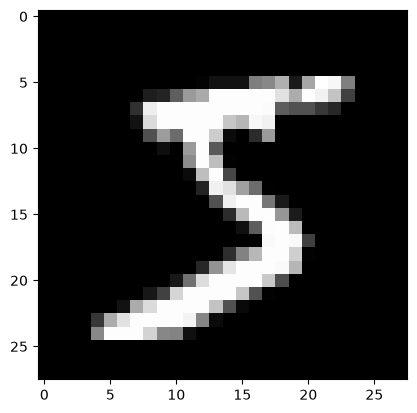

In [4]:
plt.imshow(X[0].reshape(28, 28), cmap="gray")

## Two Raw Pixels
- Pixels 350 and 406 sit near the centre of the image
- Labels only colour the plot; no method in this section sees them

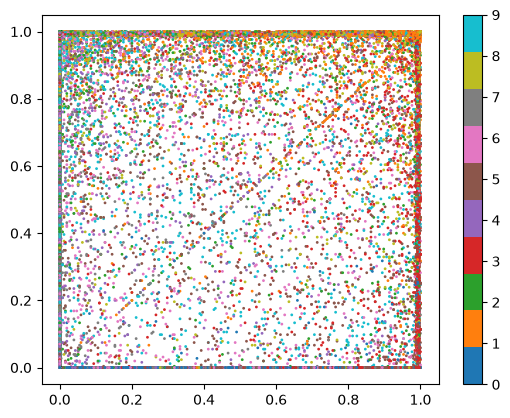

In [5]:
plt.scatter(X[:, 350], X[:, 406], c=y, s=1, cmap="tab10")
plt.colorbar()

## PCA
- Slides 5-7
- `PCA()` with no arguments keeps all 784 components

In [6]:
pca = PCA()
X_pca = pca.fit_transform(X)
pca.explained_variance_ratio_[:10]

array([0.09746116, 0.07155445, 0.06149531, 0.05403385, 0.04888934,
       0.04305227, 0.03278262, 0.02889642, 0.02758364, 0.0234214 ])

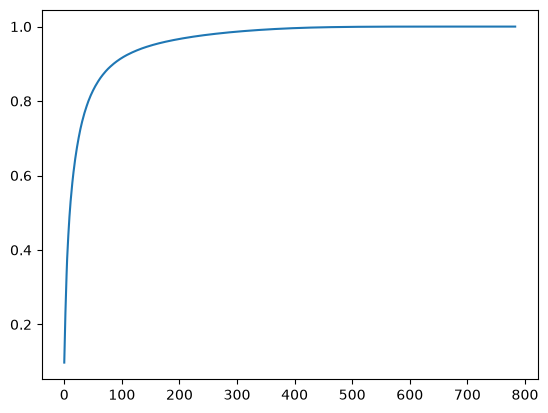

In [7]:
plt.plot(pca.explained_variance_ratio_.cumsum())

- A float `n_components` asks for that share of the variance

In [8]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X)
pca.n_components_

np.int64(154)

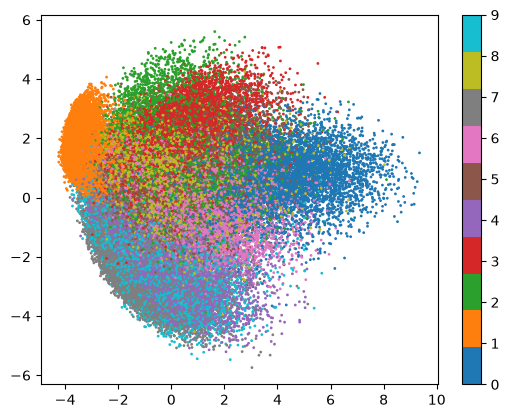

In [9]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=1, cmap="tab10")
plt.colorbar()

## Components as Images
- Slides 8-9, covering Rebuilding Digits too
- Each row of `components_` is a 784-pixel pattern

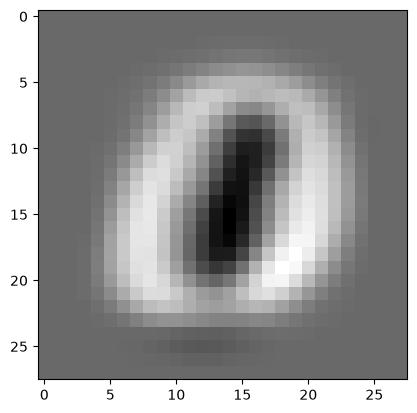

In [10]:
plt.imshow(pca.components_[0].reshape(28, 28), cmap="gray")

## Rebuilding Digits
- `inverse_transform` maps 154 numbers back to 784 pixels

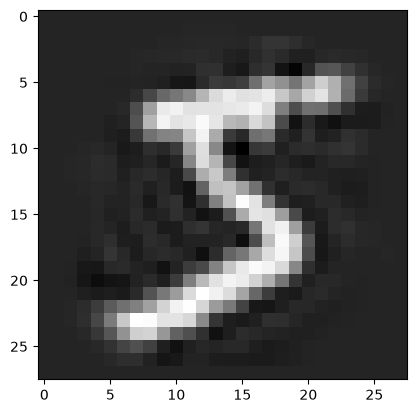

In [11]:
X_back = pca.inverse_transform(X_pca)
plt.imshow(X_back[0].reshape(28, 28), cmap="gray")

- Reconstruction error: squared pixel difference, summed per digit

In [12]:
errors = ((X - X_back) ** 2).sum(axis=1)
errors.argmax()

np.int64(13650)

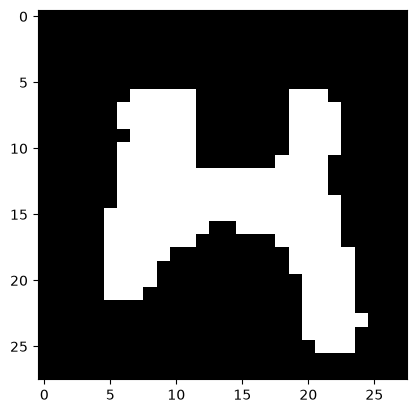

In [13]:
plt.imshow(X[errors.argmax()].reshape(28, 28), cmap="gray")

## Incremental PCA
- Slide 10
- `partial_fit` learns from one chunk at a time

In [14]:
ipca = IncrementalPCA(n_components=154)
for chunk in np.array_split(X, 20):
    ipca.partial_fit(chunk)
ipca.explained_variance_ratio_.sum(), pca.explained_variance_ratio_.sum()

(np.float64(0.9499917245596585), np.float64(0.9503499702078614))

## Sparse PCA
- Slide 11
- Fit on the first 10,000 digits, then `transform` works on all 70,000

In [15]:
spca = MiniBatchSparsePCA(n_components=50)
spca.fit(X[:10000])
X_spca = spca.transform(X)
X_spca.shape

D:\Courses\Udemy\Unsupervised-Learning-in-Python\.venv\Lib\site-packages\sklearn\linear_model\_least_angle.py:726: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 2 iterations, i.e. alpha=1.399e-04, with an active set of 2 regressors, and the smallest cholesky pivot element being 1.825e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


(70000, 50)

In [16]:
(spca.components_ == 0).mean(), (pca.components_ == 0).mean()

(np.float64(0.7553826530612245), np.float64(0.04809667373442884))

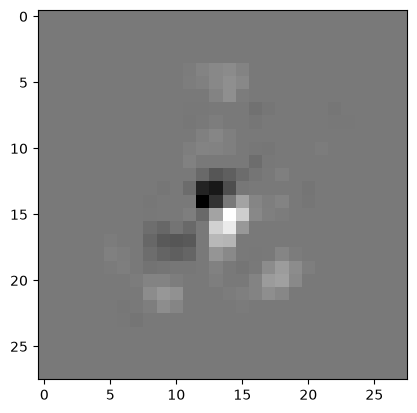

In [17]:
plt.imshow(spca.components_[0].reshape(28, 28), cmap="gray")

## Kernel PCA
- Slide 12
- The RBF kernel compares every pair of digits, so use 5,000

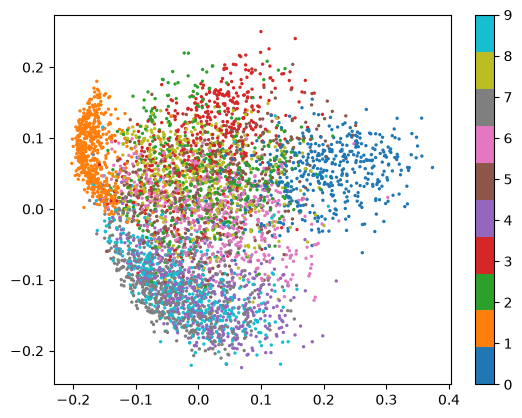

In [18]:
kpca = KernelPCA(n_components=2, kernel="rbf")
X_kpca = kpca.fit_transform(X[:5000])
plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y[:5000], s=2, cmap="tab10")
plt.colorbar()

## Truncated SVD
- Slide 13
- Same idea as PCA without centring the data first

In [19]:
svd = TruncatedSVD(n_components=154)
X_svd = svd.fit_transform(X)
svd.explained_variance_ratio_.sum()

np.float64(0.950155014333797)

## Random Projection
- Slides 14-15
- `eps` is how much any distance may stretch or shrink
- The Johnson-Lindenstrauss bound turns it into a number of dimensions

In [20]:
johnson_lindenstrauss_min_dim(70000, eps=0.5)

np.int64(535)

In [21]:
grp = GaussianRandomProjection(eps=0.5)
X_grp = grp.fit_transform(X)
X_grp.shape

(70000, 535)

In [22]:
np.linalg.norm(X[0] - X[1]), np.linalg.norm(X_grp[0] - X_grp[1])

(np.float64(9.361222132577327), np.float64(9.384318668771526))

- Sparse random projection fills most of the matrix with zeros
- `density_` is the share that is not zero

In [23]:
srp = SparseRandomProjection(eps=0.5)
X_srp = srp.fit_transform(X)
srp.density_, np.linalg.norm(X_srp[0] - X_srp[1])

(np.float64(0.03571428571428571), np.float64(9.675073889663652))

## Independent Component Analysis
- Slide 16

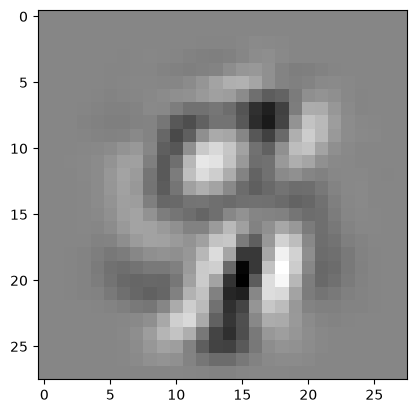

In [24]:
ica = FastICA(n_components=25)
X_ica = ica.fit_transform(X[:10000])
plt.imshow(ica.components_[0].reshape(28, 28), cmap="gray")

## Dictionary Learning
- Slide 17
- `transform_n_nonzero_coefs=5` builds each digit from at most 5 atoms

In [25]:
dl = MiniBatchDictionaryLearning(n_components=50, transform_n_nonzero_coefs=5)
X_dl = dl.fit_transform(X[:10000])
X_dl[0]

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , -1.16141112, -3.51255731,  0.        ,  1.1253931 ,
        0.        ,  0.        ,  0.        , -2.46158628,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  4.07027199,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ])

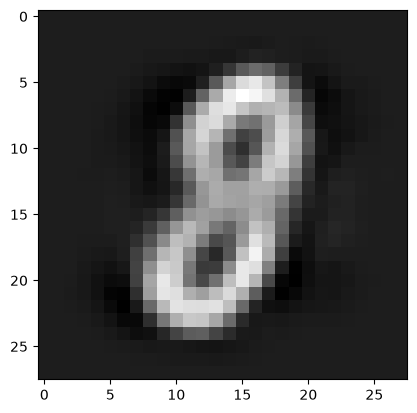

In [26]:
plt.imshow(dl.components_[0].reshape(28, 28), cmap="gray")

## Isomap, MDS and LLE
- Slides 18-19
- These compare every pair of points, so use 2,000 digits

In [27]:
X_2k, y_2k = X[:2000], y[:2000]

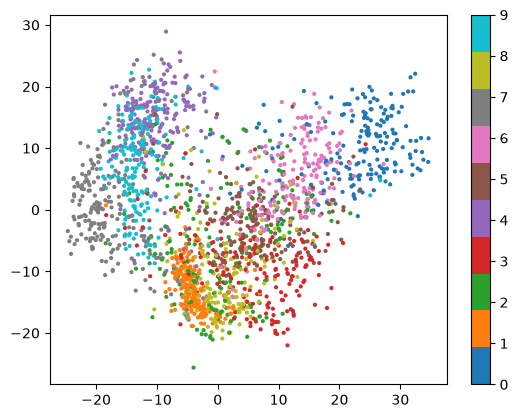

In [28]:
X_iso = Isomap(n_components=2).fit_transform(X_2k)
plt.scatter(X_iso[:, 0], X_iso[:, 1], c=y_2k, s=4, cmap="tab10")
plt.colorbar()

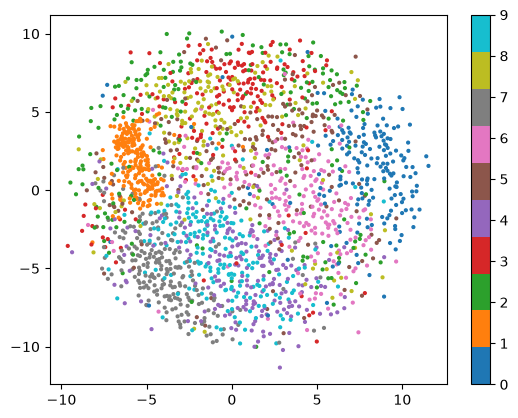

In [29]:
X_mds = MDS(n_components=2, init="classical_mds").fit_transform(X_2k)
plt.scatter(X_mds[:, 0], X_mds[:, 1], c=y_2k, s=4, cmap="tab10")
plt.colorbar()

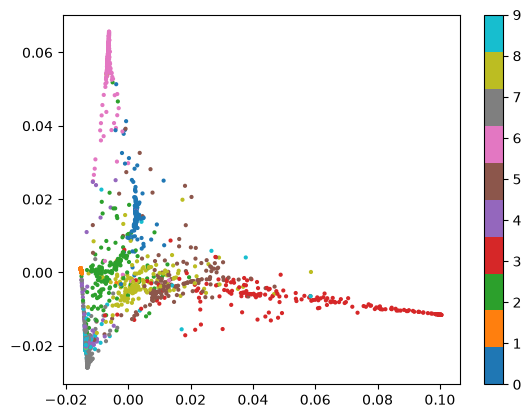

In [30]:
X_lle = LocallyLinearEmbedding(n_components=2).fit_transform(X_2k)
plt.scatter(X_lle[:, 0], X_lle[:, 1], c=y_2k, s=4, cmap="tab10")
plt.colorbar()

- Plain LLE squashes most digits onto a few lines
- Try `LocallyLinearEmbedding(n_components=2, method="modified")` in the cell above

## t-SNE
- Slides 20-21
- Input is the first 50 PCA components of 10,000 digits

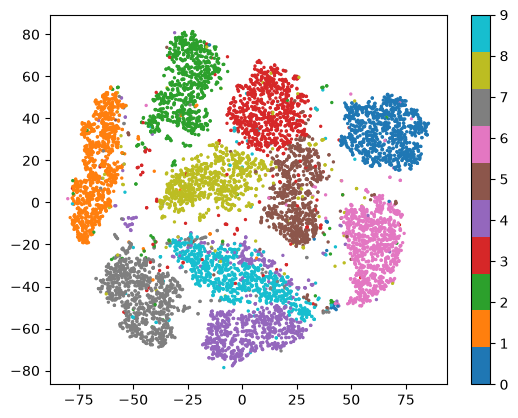

In [31]:
X_tsne = TSNE().fit_transform(X_pca[:10000, :50])
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y[:10000], s=2, cmap="tab10")
plt.colorbar()

- Try `TSNE(perplexity=5)` and `TSNE(perplexity=100)` in the cell above

## UMAP
- Slide 22
- Fit on the 60,000 training digits

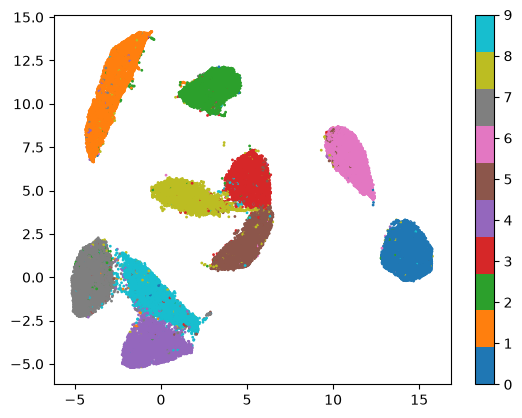

In [32]:
reducer = umap.UMAP()
X_umap = reducer.fit_transform(X[:60000])
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y[:60000], s=1, cmap="tab10")
plt.colorbar()

- Unlike t-SNE, UMAP can place new points with `transform`

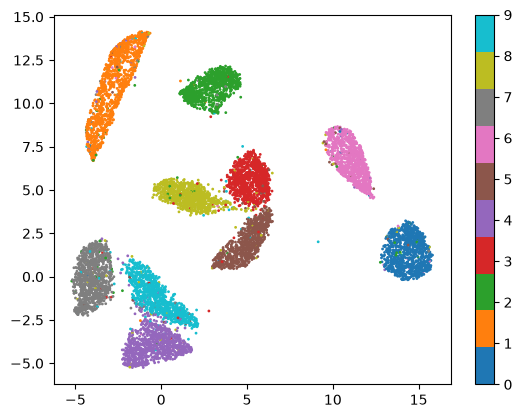

In [33]:
X_new = reducer.transform(X[60000:])
plt.scatter(X_new[:, 0], X_new[:, 1], c=y[60000:], s=1, cmap="tab10")
plt.colorbar()

## Wrap-Up
- Slides 23-25